## Q. Can CLIP place semantically matching images and text close together in the same vector space? 

In [1]:
import numpy as np 
import torch 
from PIL import Image 
from pathlib import Path 
from transformers import CLIPModel, CLIPProcessor 
import matplotlib.pyplot as plt 
import requests 

/Users/aob/AOB/CS/Projects/clip-semantic-search/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1023 20:01:01.936000 18058 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


In [2]:
if torch.cuda.is_available(): 
    device = torch.device("cuda") 
elif torch.backends.mps.is_available(): 
    device = torch.device("mps") 
else: 
    device = torch.device("cpu")

print(f"Using Device: {device}")

Using Device: mps


In [3]:
# Load the pretrained CLIP model: openai/clip-vit-base-patch32 
model_id = "openai/clip-vit-base-patch32" 
model = CLIPModel.from_pretrained(model_id).to(device) 
processor = CLIPProcessor.from_pretrained(model_id) 

Loading weights: 100%|██████████| 398/398 [00:00<00:00, 86243.70it/s]


In [4]:
model.eval() 

CLIPModel(
  (text_model): CLIPTextModel(
    (embeddings): CLIPTextEmbeddings(
      (token_embedding): Embedding(49408, 512)
      (position_embedding): Embedding(77, 512)
    )
    (encoder): CLIPEncoder(
      (layers): ModuleList(
        (0-11): 12 x CLIPEncoderLayer(
          (self_attn): CLIPAttention(
            (k_proj): Linear(in_features=512, out_features=512, bias=True)
            (v_proj): Linear(in_features=512, out_features=512, bias=True)
            (q_proj): Linear(in_features=512, out_features=512, bias=True)
            (out_proj): Linear(in_features=512, out_features=512, bias=True)
          )
          (layer_norm1): LayerNorm((512,), eps=1e-05, elementwise_affine=True, bias=True)
          (mlp): CLIPMLP(
            (activation_fn): QuickGELUActivation()
            (fc1): Linear(in_features=512, out_features=2048, bias=True)
            (fc2): Linear(in_features=2048, out_features=512, bias=True)
          )
          (layer_norm2): LayerNorm((512,), eps=1

In [5]:
# Extract the projection embedding dimension from the config 
embedding_dim = model.config.projection_dim 

In [6]:
print(f"Model Name: {model_id}") 
print(f"Selected Device: {device}")
print(f"CLIP Image/Text Embedding Dimension: {embedding_dim}")

Model Name: openai/clip-vit-base-patch32
Selected Device: mps
CLIP Image/Text Embedding Dimension: 512


In [7]:
Path.cwd() 

PosixPath('/Users/aob/AOB/CS/Projects/clip-semantic-search/notebooks')

In [8]:
project_root = Path.cwd().parent

image_dir = project_root / "data" / "images" 
image_extensions = {".jpg", ".jpeg", ".png", ".webp"} 

image_paths = sorted(
    path 
    for path in image_dir.rglob("*") 
    if path.is_file() and path.suffix.lower() in image_extensions 
)

print(f"Project Root: {project_root}")
print(f"Image directory: {image_dir}") 
print(f"Number of images found: {len(image_paths)}")

for path in image_paths[:10]: 
    print(path) 

Project Root: /Users/aob/AOB/CS/Projects/clip-semantic-search
Image directory: /Users/aob/AOB/CS/Projects/clip-semantic-search/data/images
Number of images found: 8
/Users/aob/AOB/CS/Projects/clip-semantic-search/data/images/cat.jpeg
/Users/aob/AOB/CS/Projects/clip-semantic-search/data/images/chair.jpg
/Users/aob/AOB/CS/Projects/clip-semantic-search/data/images/dog.jpg
/Users/aob/AOB/CS/Projects/clip-semantic-search/data/images/handbag.jpg
/Users/aob/AOB/CS/Projects/clip-semantic-search/data/images/jacket.jpg
/Users/aob/AOB/CS/Projects/clip-semantic-search/data/images/landscape.jpeg
/Users/aob/AOB/CS/Projects/clip-semantic-search/data/images/meal.jpg
/Users/aob/AOB/CS/Projects/clip-semantic-search/data/images/shoie.jpg


In [9]:
print(list(image_dir.iterdir()))

[PosixPath('/Users/aob/AOB/CS/Projects/clip-semantic-search/data/images/dog.jpg'), PosixPath('/Users/aob/AOB/CS/Projects/clip-semantic-search/data/images/cat.jpeg'), PosixPath('/Users/aob/AOB/CS/Projects/clip-semantic-search/data/images/jacket.jpg'), PosixPath('/Users/aob/AOB/CS/Projects/clip-semantic-search/data/images/handbag.jpg'), PosixPath('/Users/aob/AOB/CS/Projects/clip-semantic-search/data/images/shoie.jpg'), PosixPath('/Users/aob/AOB/CS/Projects/clip-semantic-search/data/images/meal.jpg'), PosixPath('/Users/aob/AOB/CS/Projects/clip-semantic-search/data/images/chair.jpg'), PosixPath('/Users/aob/AOB/CS/Projects/clip-semantic-search/data/images/landscape.jpeg')]


In [10]:
selected_paths = image_paths[:8] 

if len(selected_paths) < 5: 
    raise ValueError(f"Expected at least 5 images, but found {len(selected_paths)}")

for index, path in enumerate(selected_paths): 
    print(index, path.name)

0 cat.jpeg
1 chair.jpg
2 dog.jpg
3 handbag.jpg
4 jacket.jpg
5 landscape.jpeg
6 meal.jpg
7 shoie.jpg


In [11]:
images = [] 

for path in selected_paths: 
    image = Image.open(path).convert("RGB") 
    images.append(image) 

for path, image in zip(selected_paths, images): 
    print(f"{path.name}: mode={image.mode}, size={image.size}")

cat.jpeg: mode=RGB, size=(545, 366)
chair.jpg: mode=RGB, size=(410, 612)
dog.jpg: mode=RGB, size=(1100, 825)
handbag.jpg: mode=RGB, size=(1081, 1000)
jacket.jpg: mode=RGB, size=(493, 740)
landscape.jpeg: mode=RGB, size=(597, 335)
meal.jpg: mode=RGB, size=(740, 740)
shoie.jpg: mode=RGB, size=(2048, 2048)


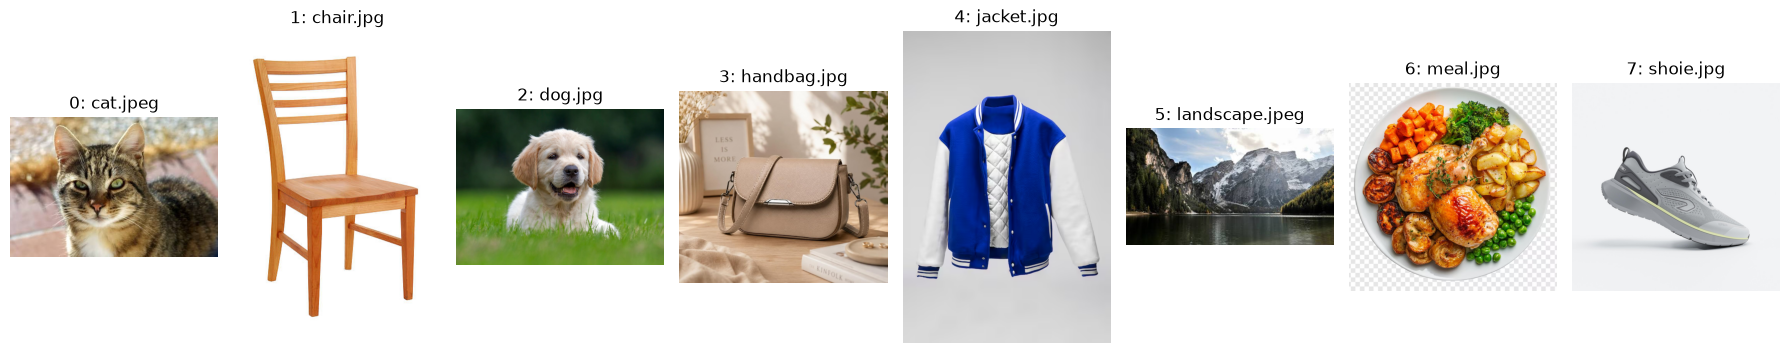

In [12]:
fig, axes = plt.subplots(1, len(images), figsize=(18,4)) 

for index, (axis, image, path) in enumerate(
    zip(axes, images, selected_paths)
): 
    axis.imshow(image) 
    axis.set_title(f"{index}: {path.name}") 
    axis.axis('off') 

plt.tight_layout() 
plt.show() 

cat.jpeg: mode=RGB, size=(545, 366)
chair.jpg: mode=RGB, size=(410, 612)
dog.jpg: mode=RGB, size=(1100, 825)
handbag.jpg: mode=RGB, size=(1081, 1000)
jacket.jpg: mode=RGB, size=(493, 740)
landscape.jpeg: mode=RGB, size=(597, 335)
meal.jpg: mode=RGB, size=(740, 740)
shoie.jpg: mode=RGB, size=(2048, 2048)


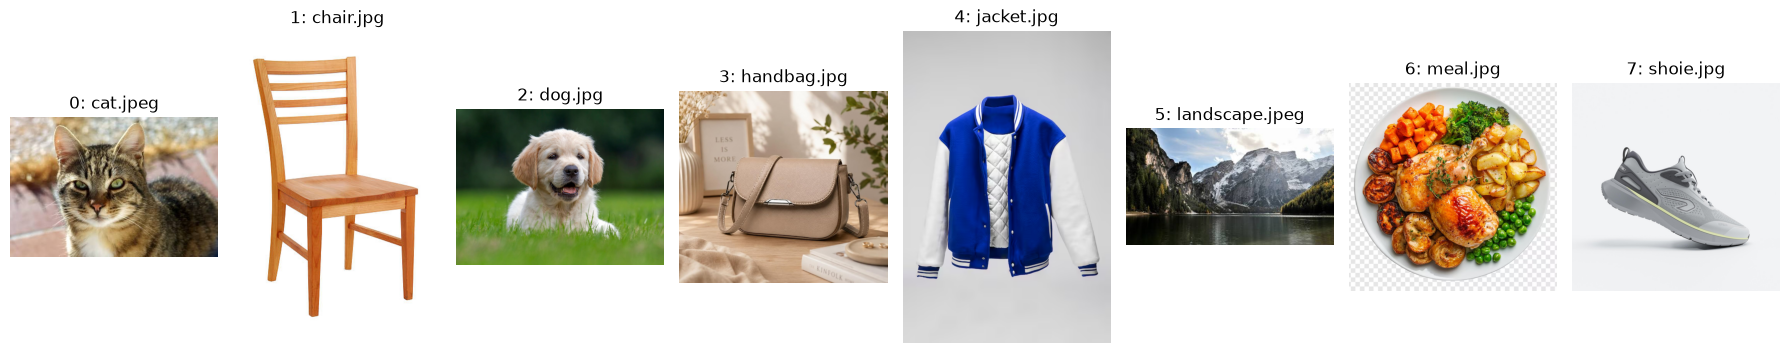

In [13]:
images = [] 

for path in image_paths: 
    image = Image.open(path).convert("RGB") 
    images.append(image) 

for path, image in zip(image_paths, images): 
    print(f"{path.name}: mode={image.mode}, size={image.size}")


fig, axes = plt.subplots(1, len(images), figsize=(18,4)) 

for index, (axis, image, path) in enumerate(
    zip(axes, images, image_paths)
): 
    axis.imshow(image) 
    axis.set_title(f"{index}: {path.name}") 
    axis.axis('off') 

plt.tight_layout() 
plt.show() 

In [14]:
image_index_to_path = {
    index: path 
    for index, path in enumerate(image_paths) 
}
image_index_to_path 

{0: PosixPath('/Users/aob/AOB/CS/Projects/clip-semantic-search/data/images/cat.jpeg'),
 1: PosixPath('/Users/aob/AOB/CS/Projects/clip-semantic-search/data/images/chair.jpg'),
 2: PosixPath('/Users/aob/AOB/CS/Projects/clip-semantic-search/data/images/dog.jpg'),
 3: PosixPath('/Users/aob/AOB/CS/Projects/clip-semantic-search/data/images/handbag.jpg'),
 4: PosixPath('/Users/aob/AOB/CS/Projects/clip-semantic-search/data/images/jacket.jpg'),
 5: PosixPath('/Users/aob/AOB/CS/Projects/clip-semantic-search/data/images/landscape.jpeg'),
 6: PosixPath('/Users/aob/AOB/CS/Projects/clip-semantic-search/data/images/meal.jpg'),
 7: PosixPath('/Users/aob/AOB/CS/Projects/clip-semantic-search/data/images/shoie.jpg')}

In [15]:
for index, path in enumerate(selected_paths): 
    print(f"{index}: {path.name}") 

0: cat.jpeg
1: chair.jpg
2: dog.jpg
3: handbag.jpg
4: jacket.jpg
5: landscape.jpeg
6: meal.jpg
7: shoie.jpg


In [16]:
# Creating a list containing one literal description per image: 
captions = [
    "cat staring aggressively",  #img 0 
    "a classic wooden chair",  # img 1 
    "a cute labrador puppy",  # img 2 
    "a light brown leather handbag",  # img 3 
    "a blue and white varsity jacket",  # img 4 
    "a beautiful landscape with snow-capped mountains and a lake",  # img 5 
    "a complete meal with meat and vegetables",  # img 6 
    "a grey sports running shoe",  # img 7
]

In [17]:
if len(captions) != len(images): 
    raise ValueError(
        f"Expected {len(images)} captions, but received {len(captions)}."
    )

for index, (path, caption) in enumerate(zip(selected_paths, captions)): 
    print(f"{index}: {path.name}") 
    print(f"    {caption}") 

0: cat.jpeg
    cat staring aggressively
1: chair.jpg
    a classic wooden chair
2: dog.jpg
    a cute labrador puppy
3: handbag.jpg
    a light brown leather handbag
4: jacket.jpg
    a blue and white varsity jacket
5: landscape.jpeg
    a beautiful landscape with snow-capped mountains and a lake
6: meal.jpg
    a complete meal with meat and vegetables
7: shoie.jpg
    a grey sports running shoe


In [18]:
mismatched_captions = captions[1:] + captions[:1] 

In [19]:
mismatched_captions

['a classic wooden chair',
 'a cute labrador puppy',
 'a light brown leather handbag',
 'a blue and white varsity jacket',
 'a beautiful landscape with snow-capped mountains and a lake',
 'a complete meal with meat and vegetables',
 'a grey sports running shoe',
 'cat staring aggressively']

In [20]:
for index, (path, caption) in enumerate(zip(selected_paths, mismatched_captions)): 
    print(f"{index}: {path.name}") 
    print(f"    Incorrect caption: {caption}")

0: cat.jpeg
    Incorrect caption: a classic wooden chair
1: chair.jpg
    Incorrect caption: a cute labrador puppy
2: dog.jpg
    Incorrect caption: a light brown leather handbag
3: handbag.jpg
    Incorrect caption: a blue and white varsity jacket
4: jacket.jpg
    Incorrect caption: a beautiful landscape with snow-capped mountains and a lake
5: landscape.jpeg
    Incorrect caption: a complete meal with meat and vegetables
6: meal.jpg
    Incorrect caption: a grey sports running shoe
7: shoie.jpg
    Incorrect caption: cat staring aggressively


In [21]:
semantic_queries = [
    "a stylish fashion item",
    "something suitable for winter",
    "a cozy object",
    "a luxury product",
    "a vintage aesthetic",
    "something minimalist",
]

In [22]:
print(f"Number of images: {len(images)}")
print(f"Number of matching captions: {len(captions)}")
print(f"Number of mismatched captions: {len(mismatched_captions)}")
print(f"Number of semantic queries: {len(semantic_queries)}")

Number of images: 8
Number of matching captions: 8
Number of mismatched captions: 8
Number of semantic queries: 6


## Generate Image Embeddings 

PIL images

    ↓

CLIP processor

    ↓

pixel_values tensor

    ↓

CLIP image encoder

    ↓

image embeddings


In [23]:
# Prepaing the images with the processor 
image_inputs = processor(
    images = images, 
    return_tensors="pt", 
)

In [24]:
print(image_inputs.keys())
print(image_inputs["pixel_values"].shape)
print(image_inputs["pixel_values"].dtype)

KeysView({'pixel_values': tensor([[[[ 1.1566,  1.1566,  1.2296,  ...,  1.2004,  1.2442,  1.2004],
          [ 1.2734,  1.2150,  1.2588,  ...,  1.2296,  1.2588,  1.2296],
          [ 1.3610,  1.2588,  1.2880,  ...,  1.1420,  1.1858,  1.1858],
          ...,
          [ 1.3318,  1.3172,  1.3026,  ..., -0.8872, -1.0769, -1.2521],
          [ 1.3026,  1.2880,  1.2734,  ..., -1.0185, -1.0185, -1.1353],
          [ 1.3026,  1.2880,  1.2588,  ..., -1.0769, -1.0331, -1.0915]],

         [[ 1.1294,  1.1294,  1.2044,  ...,  1.3995,  1.4446,  1.3995],
          [ 1.2495,  1.1894,  1.2344,  ...,  1.4295,  1.4596,  1.4295],
          [ 1.3395,  1.2344,  1.2645,  ...,  1.3395,  1.3845,  1.3845],
          ...,
          [ 0.9043,  0.8893,  0.8743,  ..., -0.9567, -1.1818, -1.3919],
          [ 0.8743,  0.8593,  0.8442,  ..., -1.1218, -1.1518, -1.2869],
          [ 0.8743,  0.8593,  0.8292,  ..., -1.1818, -1.1518, -1.2568]],

         [[ 1.1221,  1.1221,  1.1932,  ...,  1.4491,  1.4918,  1.4491],
    

### torch.Size([8, 3, 224, 224]) 

These dimensions mean: 
* 8 -> number of images 
* 3 -> RGB Channels 
* 224x224 -> CLIP's expected image size 

In [25]:
# Moving the input tensor to MPS 
image_inputs = {
    key: value.to(device) 
    for key, value in image_inputs.items() 
}

In [26]:
print(image_inputs["pixel_values"].device)

mps:0


In [27]:
# Generate the embeddings 
with torch.no_grad(): 
    vision_outputs = model.vision_model(
        pixel_values=image_inputs["pixel_values"]
    )

    image_embeddings = model.visual_projection(
        vision_outputs.pooler_output 
    )

In [28]:
print(type(image_embeddings))
print(image_embeddings.shape)
print(image_embeddings.dtype)
print(image_embeddings.device)

<class 'torch.Tensor'>
torch.Size([8, 512])
torch.float32
mps:0


In [29]:
image_embeddings_np = (
    image_embeddings 
    .detach() # removes the tensor from any gradient graph 
    .cpu()  # moves it from MPS to CPU memory 
    .numpy() # converts it into a NumPy array 
)

print(image_embeddings_np.shape) 
print(image_embeddings_np.dtype) 

(8, 512)
float32


In [30]:
if image_embeddings.shape[0] != len(images): 
    raise ValueError(
        "The number of image embeddings does not match the number of images."
    )

if image_embeddings.shape[1] != 512: 
    raise ValueError(
        f"Expected embedding dimension 512, got {image_embeddings.shape[1]}."
    )

for index, path in enumerate(selected_paths): 
    print(
        f"{index}: {path.name} -> "
        f"embedding shape {tuple(image_embeddings[index].shape)}" 
    )

0: cat.jpeg -> embedding shape (512,)
1: chair.jpg -> embedding shape (512,)
2: dog.jpg -> embedding shape (512,)
3: handbag.jpg -> embedding shape (512,)
4: jacket.jpg -> embedding shape (512,)
5: landscape.jpeg -> embedding shape (512,)
6: meal.jpg -> embedding shape (512,)
7: shoie.jpg -> embedding shape (512,)


In [31]:
print(image_embeddings[0][:10])

tensor([-0.0128, -0.2554,  0.1175, -0.4845, -0.4122, -0.4734,  0.0851,  0.5135,
         0.3215, -0.1912], device='mps:0')


In [32]:
print(f"Pixel Values Shape: {image_inputs["pixel_values"].shape}") 
print(f"Image Embeddings Shape: {image_embeddings.shape}") 
print(f"Image Embeddings NumPy Shape: {image_embeddings_np.shape}") 
print(f"Device: {image_embeddings.device}")

Pixel Values Shape: torch.Size([8, 3, 224, 224])
Image Embeddings Shape: torch.Size([8, 512])
Image Embeddings NumPy Shape: (8, 512)
Device: mps:0


In [33]:
image_embeddings[3]

tensor([-3.0220e-01,  9.1755e-02,  6.6052e-02,  5.8734e-01,  4.4298e-03,
         2.9141e-01, -7.0329e-02,  1.8589e-01, -2.1805e-02,  6.3872e-01,
         2.0295e-01, -3.9812e-01,  4.3653e-01,  1.4323e-01,  6.5245e-01,
        -3.3209e-01, -8.1285e-01,  6.1999e-02, -3.1954e-02, -2.8092e-01,
         2.5676e-01, -2.4796e-01,  3.6615e-01, -1.4895e-01, -1.9291e-01,
         1.3658e-02, -4.2305e-02, -1.2083e-01, -6.9466e-02,  1.8470e-01,
         1.5763e-01, -2.4250e-01, -1.6190e-01, -6.4989e-01,  7.9976e-02,
        -1.9623e-01, -8.2392e-02,  3.4439e-02,  2.7586e-01,  1.0850e+00,
        -2.8867e-01, -1.2058e-01,  3.4802e-01,  3.8655e-02,  6.7040e-01,
        -9.4538e-01,  2.2263e-01,  1.9977e-01,  4.5289e-02,  4.0018e-01,
         2.8568e-01, -5.7469e-01,  3.7195e-01,  3.5372e-01,  1.2687e-01,
         2.1896e-01,  4.2762e-01,  2.9762e-01,  2.3423e-01,  1.7620e-01,
        -2.6415e-01, -3.3135e-01,  1.1590e-01, -4.0897e-02, -1.7599e-01,
        -2.4117e-01, -2.9624e-01, -1.0849e+00,  3.3

## Generate Text Embeddings 

Text Pipeline:

caption strings

    ↓

processor/tokenizer

    ↓

token IDs

    ↓

CLIP text encoder

    ↓

text projection

    ↓

text embeddings


In [34]:
text_inputs = processor(
    text=captions, 
    padding=True,  # Pads all the captions so that tokenized captions are of the same length 
    return_tensors="pt",  # Requests PyTorch tensors as the output 
)

In [35]:
print(text_inputs.keys())

KeysView({'input_ids': tensor([[49406,  2368, 13800, 48667, 49407, 49407, 49407, 49407, 49407, 49407,
         49407, 49407, 49407],
        [49406,   320,  2713,  9057,  4269, 49407, 49407, 49407, 49407, 49407,
         49407, 49407, 49407],
        [49406,   320,  2242, 25409,  6829, 49407, 49407, 49407, 49407, 49407,
         49407, 49407, 49407],
        [49406,   320,  1395,  2866,  5862, 22654, 49407, 49407, 49407, 49407,
         49407, 49407, 49407],
        [49406,   320,  1746,   537,  1579,  8574,  6164, 49407, 49407, 49407,
         49407, 49407, 49407],
        [49406,   320,  1215,  5727,   593,  2583,   268, 24659,  5873,   537,
           320,  2553, 49407],
        [49406,   320,  3263,  5478,   593,  6480,   537, 14119, 49407, 49407,
         49407, 49407, 49407],
        [49406,   320,  5046,  2054,  2761,  7342, 49407, 49407, 49407, 49407,
         49407, 49407, 49407]]), 'attention_mask': tensor([[1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0],
        [1, 1, 1, 1, 1, 1, 0

In [36]:
print("input_ids shape:", text_inputs["input_ids"].shape) 
print("attention_mask shape:", text_inputs["attention_mask"].shape) 

input_ids shape: torch.Size([8, 13])
attention_mask shape: torch.Size([8, 13])


#### `input_ids` - These are integer IDs representing tokens. For example, a sentence is not directly sent into the neural network as text: `"a cute labrador puppy"` It is converted into numbers representing pieces of words. 

#### `attention_mask` - This tells the model which positions contain real tokens and which positions are padding added only to make the batch rectangular. 

In [37]:
# Move text inputs into MPS 
text_inputs = {
    key: value.to(device) 
    for key, value in text_inputs.items() 
}

In [38]:
for key, value in text_inputs.items(): 
    print(key, value.device) 

input_ids mps:0
attention_mask mps:0


In [39]:
# Run the text encoder | Create the text representation 
with torch.no_grad(): 
    text_outputs = model.text_model(
        input_ids=text_inputs["input_ids"], 
        attention_mask=text_inputs["attention_mask"],
    )

In [40]:
print(type(text_outputs))
print(text_outputs.keys())

<class 'transformers.modeling_outputs.BaseModelOutputWithPooling'>
odict_keys(['last_hidden_state', 'pooler_output'])


In [41]:
print(text_outputs.pooler_output.shape)

torch.Size([8, 512])


In [42]:
# Apply the text projection 
with torch.no_grad(): 
    text_embeddings = model.text_projection(
        text_outputs.pooler_output
    )

In [43]:
print(type(text_embeddings))
print(text_embeddings.shape) 
print(text_embeddings.dtype) 
print(text_embeddings.device) 

<class 'torch.Tensor'>
torch.Size([8, 512])
torch.float32
mps:0


In [44]:
# Convert text embeddings to NumPy 

text_embeddings_np = (
    text_embeddings
    .detach() 
    .cpu() 
    .numpy() 
)

print(text_embeddings_np.shape)
print(text_embeddings_np.dtype)

(8, 512)
float32


In [45]:
if image_embeddings_np.shape != text_embeddings_np.shape: 
    raise ValueError(
        "Image and text emebddings must have the same shape."
    )

print("Image embeddings:", image_embeddings_np.shape) 
print("Text embeddings:", text_embeddings_np.shape)

Image embeddings: (8, 512)
Text embeddings: (8, 512)


In [46]:
for index, (path, caption) in enumerate(zip(selected_paths, captions)): 
    print(f"{index}: {path.name} <-> {caption}")

0: cat.jpeg <-> cat staring aggressively
1: chair.jpg <-> a classic wooden chair
2: dog.jpg <-> a cute labrador puppy
3: handbag.jpg <-> a light brown leather handbag
4: jacket.jpg <-> a blue and white varsity jacket
5: landscape.jpeg <-> a beautiful landscape with snow-capped mountains and a lake
6: meal.jpg <-> a complete meal with meat and vegetables
7: shoie.jpg <-> a grey sports running shoe


## **Normalize the embeddings** 

### Why are we normalizing ? 

Each vector has: 

* a **direction**, representing its semantic meaning 
* a **length/magnitude**, which can vary 

For semantic comparision, we mainly care about direction. Cosine similarity measures how closesly two vectors point in the same direction. 

For a vector (x), normalization means: 

`normalized_x = x / length_of_x`

After normalization, every vector has length approximately `1`. 

Then: 

`dot product of normalized vectors = cosine similarity` 

We will normalize image and text vectors separately, but in the same way. 

In [47]:
# Calculate the vector norms 
image_norms = np.linalg.norm(image_embeddings_np, axis=1) 
text_norms = np.linalg.norm(text_embeddings_np, axis=1) 

print("Image norms:", image_norms) 
print("Text norms:", text_norms) 

Image norms: [11.471004  10.981943  11.008319  10.312421  10.9621725 10.13873
 10.371045   9.71842  ]
Text norms: [ 9.959326   9.121315   8.89397    7.6232414  7.0910764  7.627539
 11.220584   8.630618 ]


In [48]:
# Normalize every row 
image_embeddings_normalized = (
    image_embeddings_np / image_norms[:, np.newaxis] 
)

text_embeddings_normalized = (
    text_embeddings_np / text_norms[:, np.newaxis]
)

In [49]:
normalized_image_norms = np.linalg.norm(
    image_embeddings_normalized, 
    axis=1
)
normalized_text_norms = np.linalg.norm(
    text_embeddings_normalized, 
    axis=1
)

print("Normalized image norms:")
print(normalized_image_norms)

print("\nNormalized text norms:")
print(normalized_text_norms)

Normalized image norms:
[1.         1.         1.         1.         1.         0.99999994
 1.         1.0000001 ]

Normalized text norms:
[1.         0.9999999  1.         0.99999994 1.         1.
 1.         1.        ]


In [50]:
# Manual Cosine Similarity  - Cat Image 
cat_image = image_embeddings_np[0] 
cat_caption = text_embeddings_np[0]

cat_similarity = np.dot(cat_image, cat_caption) / (np.linalg.norm(cat_image) * np.linalg.norm(cat_caption))

print("Cat image <-> cat caption similarity:", cat_similarity)

Cat image <-> cat caption similarity: 0.25985837


In [51]:
cat_similarity_normalized = np.dot(
    image_embeddings_normalized[0], 
    text_embeddings_normalized[0], 
)

print(
    "Using normalized vectors:", 
    cat_similarity_normalized,
)

Using normalized vectors: 0.2598583


## Calculate the full image-text similarity matrix 

In [52]:
similarity_matrix_loop = np.zeros(
    (len(images), len(captions)), 
    dtype=np.float32, 
)

for image_index in range(len(images)): 
    for caption_index in range(len(captions)): 
        image_vector = image_embeddings_np[image_index] 
        text_vector = text_embeddings_np[caption_index]

        similarity_matrix_loop[image_index, caption_index] = (
            np.dot(image_vector, text_vector) 
            / (
                np.linalg.norm(image_vector)
                * np.linalg.norm(text_vector)
            )
        )

print(similarity_matrix_loop.shape)
print(similarity_matrix_loop)

(8, 8)
[[0.25985837 0.17557862 0.16651717 0.16717598 0.16216375 0.10646974
  0.16731218 0.16730571]
 [0.21575162 0.3066037  0.1687088  0.17327377 0.17207964 0.11870557
  0.22300042 0.15187651]
 [0.18691137 0.20045355 0.30126846 0.1637859  0.19120412 0.12993114
  0.19162388 0.16719231]
 [0.14913337 0.17957136 0.15039958 0.31846347 0.14237264 0.12418931
  0.15678576 0.14562103]
 [0.158984   0.16349965 0.15774922 0.11996069 0.35452628 0.13019204
  0.1781348  0.13894258]
 [0.13254406 0.16981298 0.13533114 0.13065177 0.15373535 0.2843096
  0.17112836 0.16589807]
 [0.16882943 0.16213313 0.1394563  0.121203   0.1609487  0.08328286
  0.27121332 0.16236557]
 [0.15345709 0.12983403 0.14597994 0.10293306 0.08075181 0.09249409
  0.17718457 0.3191629 ]]


In [53]:
similarity_matrix = (
    image_embeddings_normalized 
    @ text_embeddings_normalized.T 
)

print(similarity_matrix.shape) 
print(similarity_matrix)

(8, 8)
[[0.25985837 0.17557847 0.16651715 0.16717602 0.16216376 0.10646974
  0.16731213 0.16730568]
 [0.21575168 0.30660385 0.16870879 0.17327367 0.17207968 0.11870557
  0.22300045 0.1518765 ]
 [0.18691133 0.20045364 0.3012685  0.16378587 0.19120407 0.12993118
  0.1916238  0.16719228]
 [0.1491333  0.1795714  0.1503996  0.31846341 0.14237265 0.12418933
  0.1567858  0.145621  ]
 [0.15898405 0.16349968 0.15774924 0.11996068 0.35452598 0.13019197
  0.17813478 0.13894264]
 [0.13254413 0.16981296 0.13533103 0.13065174 0.15373525 0.28430954
  0.17112829 0.16589811]
 [0.16882943 0.16213326 0.13945633 0.12120304 0.16094868 0.0832829
  0.2712135  0.16236553]
 [0.15345713 0.129834   0.14597991 0.10293303 0.08075182 0.09249409
  0.17718466 0.31916294]]


In [54]:
difference = np.max(np.abs(similarity_matrix_loop - similarity_matrix)) 

print("Maximum difference:", difference) 

Maximum difference: 2.9802322e-07


In [55]:
for image_index, path in enumerate(selected_paths): 
    print(f"\nImage {image_index}: {path.name}") 

    for caption_index, caption in enumerate(captions): 
        score = similarity_matrix[image_index, caption_index] 

        print(
            f"  Caption {caption_index}: " 
            f"{score:.4f} - {caption}"
        )


Image 0: cat.jpeg
  Caption 0: 0.2599 - cat staring aggressively
  Caption 1: 0.1756 - a classic wooden chair
  Caption 2: 0.1665 - a cute labrador puppy
  Caption 3: 0.1672 - a light brown leather handbag
  Caption 4: 0.1622 - a blue and white varsity jacket
  Caption 5: 0.1065 - a beautiful landscape with snow-capped mountains and a lake
  Caption 6: 0.1673 - a complete meal with meat and vegetables
  Caption 7: 0.1673 - a grey sports running shoe

Image 1: chair.jpg
  Caption 0: 0.2158 - cat staring aggressively
  Caption 1: 0.3066 - a classic wooden chair
  Caption 2: 0.1687 - a cute labrador puppy
  Caption 3: 0.1733 - a light brown leather handbag
  Caption 4: 0.1721 - a blue and white varsity jacket
  Caption 5: 0.1187 - a beautiful landscape with snow-capped mountains and a lake
  Caption 6: 0.2230 - a complete meal with meat and vegetables
  Caption 7: 0.1519 - a grey sports running shoe

Image 2: dog.jpg
  Caption 0: 0.1869 - cat staring aggressively
  Caption 1: 0.2005 - a 

In [56]:
diagonal_scores = np.diag(similarity_matrix) 

for index, (path, caption, score) in enumerate( 
    zip(selected_paths, captions, diagonal_scores) 
): 
    print(
        f"{index}: {path.name} <-> {caption} "
        f"-> {score:.4f}" 
    )

0: cat.jpeg <-> cat staring aggressively -> 0.2599
1: chair.jpg <-> a classic wooden chair -> 0.3066
2: dog.jpg <-> a cute labrador puppy -> 0.3013
3: handbag.jpg <-> a light brown leather handbag -> 0.3185
4: jacket.jpg <-> a blue and white varsity jacket -> 0.3545
5: landscape.jpeg <-> a beautiful landscape with snow-capped mountains and a lake -> 0.2843
6: meal.jpg <-> a complete meal with meat and vegetables -> 0.2712
7: shoie.jpg <-> a grey sports running shoe -> 0.3192


In [57]:
best_caption_indices = np.argmax(
    similarity_matrix, 
    axis=1, 
)

for image_index, caption_index in enumerate(best_caption_indices): 
    print(
        f"Image: {selected_paths[image_index].name}" 
    )
    print(
        f"Best caption: {captions[caption_index]}"
    )
    print(
        f"Score: {similarity_matrix[image_index, caption_index]:.4f}"
    )
    print() 
    

Image: cat.jpeg
Best caption: cat staring aggressively
Score: 0.2599

Image: chair.jpg
Best caption: a classic wooden chair
Score: 0.3066

Image: dog.jpg
Best caption: a cute labrador puppy
Score: 0.3013

Image: handbag.jpg
Best caption: a light brown leather handbag
Score: 0.3185

Image: jacket.jpg
Best caption: a blue and white varsity jacket
Score: 0.3545

Image: landscape.jpeg
Best caption: a beautiful landscape with snow-capped mountains and a lake
Score: 0.2843

Image: meal.jpg
Best caption: a complete meal with meat and vegetables
Score: 0.2712

Image: shoie.jpg
Best caption: a grey sports running shoe
Score: 0.3192



In [58]:
expected_caption_indices = np.arange(len(captions)) 

correct_count = np.sum(
    best_caption_indices == expected_caption_indices
)

accuracy = correct_count / len(captions) 

print(f"Correct matches: {correct_count}/{len(captions)}")
print(f"Matching accuracy: {accuracy:.2%}")

Correct matches: 8/8
Matching accuracy: 100.00%


In [60]:
# Compare against the mismatched captions 
mismatched_text_inputs = processor(
    text=mismatched_captions, 
    padding=True, 
    return_tensors="pt", 
)

mismatched_text_inputs = {
    key: value.to(device) 
    for key, value in mismatched_text_inputs.items() 
}

In [62]:
# Generate their embeddings 
with torch.no_grad(): 
    mismatch_text_outputs = model.text_model(
        input_ids=mismatched_text_inputs["input_ids"], 
        attention_mask=mismatched_text_inputs["attention_mask"], 
    )
    mismatched_text_embeddings = model.text_projection(
        mismatch_text_outputs.pooler_output
    )

In [63]:
# convert and normalize them: 
mismatched_text_embeddings_np = (
    mismatched_text_embeddings 
    .detach() 
    .cpu() 
    .numpy() 
)

mismatched_text_norms = np.linalg.norm(
    mismatched_text_embeddings_np, 
    axis=1
)

mismatched_text_embeddings_normalized = (
    mismatched_text_embeddings_np 
    / mismatched_text_norms[:, np.newaxis]
)

In [64]:
mismatched_similarity_matrix = (
    image_embeddings_normalized 
    @ mismatched_text_embeddings_normalized.T 
)

In [65]:
matching_scores = np.diag(similarity_matrix) 
mismatched_scores = np.diag(mismatched_similarity_matrix) 

print("Matching scores:")
print(matching_scores) 

print("\nMismatched scores:") 
print(mismatched_scores)

print("\nAverage matching score:", matching_scores.mean())
print("Average mismatched score:", mismatched_scores.mean())

Matching scores:
[0.25985837 0.30660385 0.3012685  0.31846341 0.35452598 0.28430954
 0.2712135  0.31916294]

Mismatched scores:
[0.17557847 0.16870879 0.16378587 0.14237265 0.13019197 0.17112829
 0.16236553 0.15345713]

Average matching score: 0.30192578
Average mismatched score: 0.15844859


In [67]:
# Run one semantic query 
query = "a stylish fashion item" 

In [68]:
image_embeddings_normalized.shape

(8, 512)

In [69]:
print(query) 

a stylish fashion item


In [70]:
query_batch = [query] 

print(query_batch) 
print(type(query_batch)) 
print(len(query_batch))

['a stylish fashion item']
<class 'list'>
1


In [71]:
# Tokenize the query 
query_inputs = processor(
    text=query_batch, 
    padding=True, 
    return_tensors="pt", 
)

In [72]:
print(query_inputs)
print("input_ids shape:", query_inputs["input_ids"].shape)
print("attention_mask shape:", query_inputs["attention_mask"].shape)

{'input_ids': tensor([[49406,   320, 10378,  2444,  8532, 49407]]), 'attention_mask': tensor([[1, 1, 1, 1, 1, 1]])}
input_ids shape: torch.Size([1, 6])
attention_mask shape: torch.Size([1, 6])


In [73]:
query_inputs = {
    key: value.to(device) 
    for key, value in query_inputs.items() 
}

In [74]:
for key, value in query_inputs.items():
    print(key)
    print("  type:", type(value))
    print("  shape:", value.shape)
    print("  device:", value.device)

input_ids
  type: <class 'torch.Tensor'>
  shape: torch.Size([1, 6])
  device: mps:0
attention_mask
  type: <class 'torch.Tensor'>
  shape: torch.Size([1, 6])
  device: mps:0


In [75]:
# Run the text encoder 
with torch.no_grad(): 
    query_outputs = model.text_model(
        input_ids=query_inputs["input_ids"], 
        attention_mask=query_inputs["attention_mask"], 
    )

In [76]:
print(type(query_outputs)) 
print(query_outputs.keys())
print("Pooler output shape:", query_outputs.pooler_output.shape)

<class 'transformers.modeling_outputs.BaseModelOutputWithPooling'>
odict_keys(['last_hidden_state', 'pooler_output'])
Pooler output shape: torch.Size([1, 512])


In [77]:
# Apply CLIP's text projection 
with torch.no_grad(): 
    query_embedding = model.text_projection(
        query_outputs.pooler_output
    )

In [78]:
print(type(query_embedding))
print("Shape:", query_embedding.shape)  
print("Dtype:", query_embedding.dtype) 
print("Device:", query_embedding.device) 

<class 'torch.Tensor'>
Shape: torch.Size([1, 512])
Dtype: torch.float32
Device: mps:0


In [79]:
query_embedding_np = (
    query_embedding 
    .detach() 
    .cpu() 
    .numpy() 
)

In [80]:
print(type(query_embedding_np))
print(query_embedding_np.shape)
print(query_embedding_np.dtype)

<class 'numpy.ndarray'>
(1, 512)
float32


In [81]:
# Normalize the query vector 
query_norm = np.linalg.norm(
    query_embedding_np, 
    axis=1, 
)
print("Query norm:", query_norm) 

Query norm: [11.230078]


In [82]:
query_norm.shape 

(1,)

In [83]:
query_embedding_normalized = (
    query_embedding_np 
    / query_norm[:, np.newaxis]
)

In [85]:
print("Normalized query shape:", query_embedding_normalized.shape)
print(
    "Normalized query norm:",
    np.linalg.norm(query_embedding_normalized, axis=1),
)

Normalized query shape: (1, 512)
Normalized query norm: [0.99999994]


In [86]:
# Compare the query with all images 
query_image_scores = (
    image_embeddings_normalized 
    @ query_embedding_normalized.T 
)

In [87]:
print(image_embeddings_normalized.shape) 
print(query_embedding_normalized.shape)

(8, 512)
(1, 512)


In [88]:
print(query_image_scores.shape) 
print(query_image_scores)

(8, 1)
[[0.18531425]
 [0.24063446]
 [0.19596437]
 [0.2549618 ]
 [0.26372576]
 [0.14854321]
 [0.1948534 ]
 [0.22798328]]


In [89]:
# Flatten the scores 
query_image_scores = query_image_scores.ravel() 

print(query_image_scores.shape) 
print(query_image_scores) 

(8,)
[0.18531425 0.24063446 0.19596437 0.2549618  0.26372576 0.14854321
 0.1948534  0.22798328]


In [90]:
ranked_indices = np.argsort(
    query_image_scores 
)[::-1]

In [91]:
print(ranked_indices)

[4 3 1 7 2 6 0 5]


In [94]:
print(f"Query: {query}\n")

for rank, image_index in enumerate(ranked_indices, start=1): 
    image_path = selected_paths[image_index] 
    score = query_image_scores[image_index] 

    print(
        f"{rank}. {image_path.name} " 
        f"(score: {score:.4f})"   
    )

Query: a stylish fashion item

1. jacket.jpg (score: 0.2637)
2. handbag.jpg (score: 0.2550)
3. chair.jpg (score: 0.2406)
4. shoie.jpg (score: 0.2280)
5. dog.jpg (score: 0.1960)
6. meal.jpg (score: 0.1949)
7. cat.jpeg (score: 0.1853)
8. landscape.jpeg (score: 0.1485)


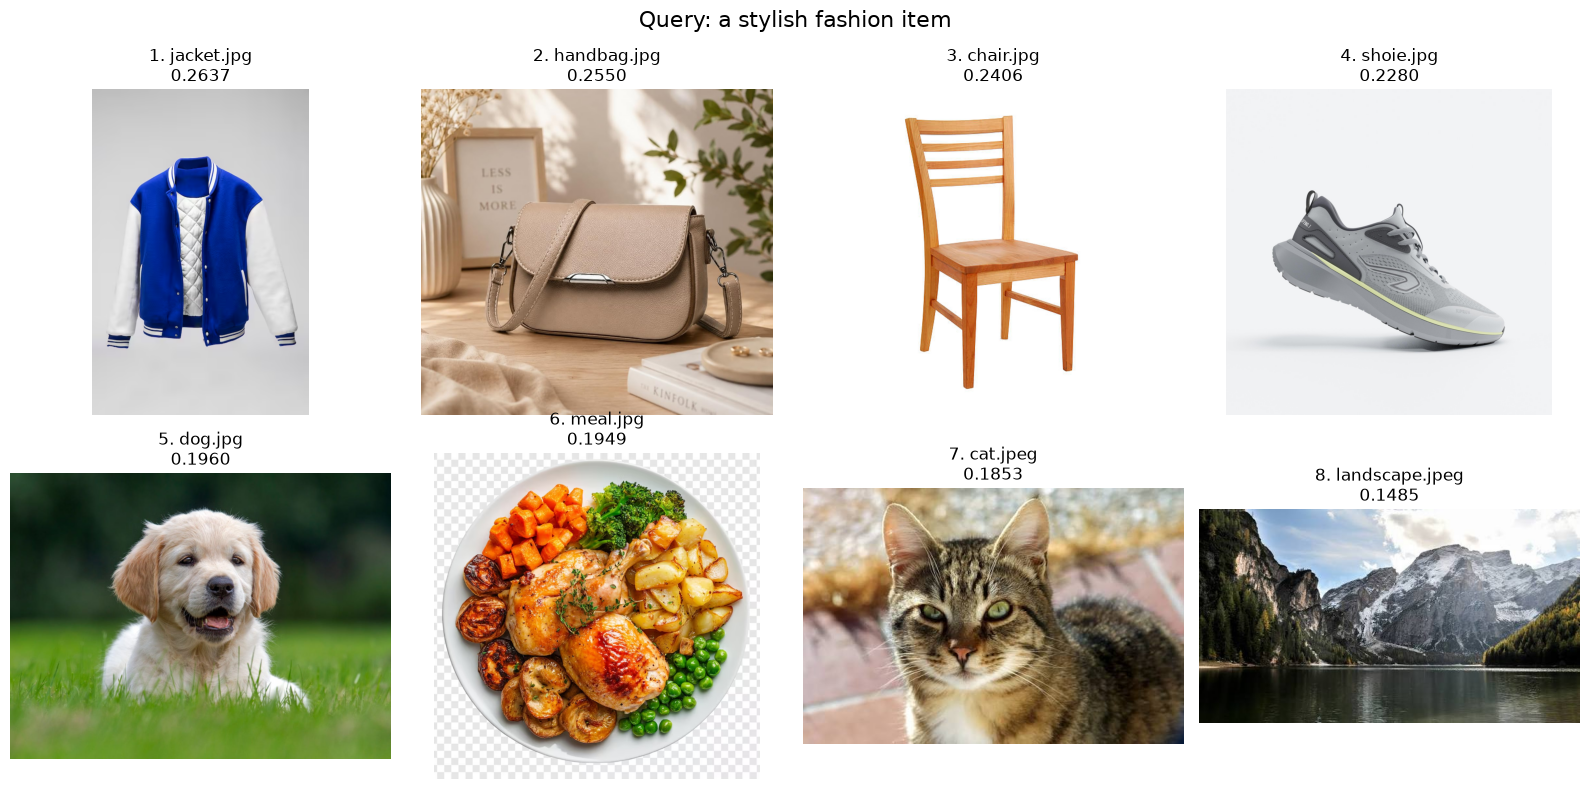

In [95]:
fig, axes = plt.subplots(2,4,figsize=(16,8)) 

for rank, (axis, image_index) in enumerate(
    zip(axes.flat, ranked_indices), 
    start=1, 
): 
    axis.imshow(images[image_index])
    axis.set_title(
        f"{rank}. {selected_paths[image_index].name}\n" 
        f"{query_image_scores[image_index]:.4f}" 
    )
    axis.axis("off") 

fig.suptitle(f"Query: {query}", fontsize=16) 
plt.tight_layout() 
plt.show()